# 01 · Análisis exploratorio de datos (T-008)
**Scoring predictivo de admisión de consultas — Carna, Mango & Asoc.**

> **Advertencia de procedencia.** `Carna_Dataset_Simulado.xlsx` es un conjunto de datos **100% simulado**. No presentar ninguna cifra derivada de él como dato real del estudio. Los resultados de este notebook describen los supuestos incorporados en la simulación, no el proceso real de admisión.

Objetivo (fase *Comprensión de los datos* de CRISP-DM): describir distribuciones, valores faltantes y atípicos, y la relación de cada predictor con la variable objetivo, verificando que las proporciones resultantes sean consistentes con los parámetros relevados en el Módulo 2.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore", message="IProgress not found")
import pandas as pd
import matplotlib.pyplot as plt
from src.features import load_dataset
from src.constants import PREDICTORS, DOMAINS

BLUE, RED, GREY = "#2a78d6", "#e34948", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "axes.axisbelow": True, "figure.dpi": 110})

df = load_dataset()
print(df.shape)
df.head()

(1224, 14)


,id_consulta,fecha_consulta,canal_ingreso,area_practica,tipo_reclamo,jurisdiccion,monto_estimado,estado_prescripcion,documentacion_aportada,socio_evaluador,resultado_admision,motivo_rechazo,resultado_final_caso,observaciones
0,C-2024-0001,2024-09-02,Referido,Civil,Cobro de deuda,Provincia de Buenos Aires,4410000.0,Vigente,Completa,Socio 1,Aceptada,NaN,Ganado,Consulta con posible instancia conciliatoria
1,C-2024-0002,2024-09-02,Referido,Consumidor,Daños por producto defectuoso,CABA,2250000.0,Por vencer (menos de 6 meses),Ninguna,Socio 2,Rechazada,Documentación insuficiente,No aplica,NaN
2,C-2024-0003,2024-09-02,Teléfono,Laboral,Horas extras impagas,CABA,1920000.0,Vigente,Parcial,Socio 1,Aceptada,NaN,Ganado,NaN
3,C-2024-0004,2024-09-03,Referido,Laboral,Créditos laborales por acoso,Provincia de Buenos Aires,NaN,Vigente,Parcial,Socio 1,Rechazada,Falta de viabilidad probatoria,No aplica,NaN
4,C-2024-0005,2024-09-03,Formulario web,Civil,Cobro de deuda,Provincia de Buenos Aires,1260000.0,Vigente,Completa,Socio 2,Aceptada,NaN,Ganado,Se solicitó ampliar antecedentes


## 1. Estructura, tipos y valores faltantes

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1224 entries, 0 to 1223
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_consulta             1224 non-null   object 
 1   fecha_consulta          1224 non-null   object 
 2   canal_ingreso           1224 non-null   object 
 3   area_practica           1224 non-null   object 
 4   tipo_reclamo            1224 non-null   object 
 5   jurisdiccion            1224 non-null   object 
 6   monto_estimado          1086 non-null   float64
 7   estado_prescripcion     1224 non-null   object 
 8   documentacion_aportada  1224 non-null   object 
 9   socio_evaluador         1224 non-null   object 
 10  resultado_admision      1224 non-null   object 
 11  motivo_rechazo          511 non-null    object 
 12  resultado_final_caso    1224 non-null   object 
 13  observaciones           301 non-null    object 
dtypes: float64(1), object(13)
memory usage: 

In [3]:
missing = df.isna().mean().mul(100).round(1).rename("% nulos")
missing[missing > 0]

monto_estimado    11.3
motivo_rechazo    58.3
observaciones     75.4
Name: % nulos, dtype: float64

Solo `monto_estimado` presenta faltantes entre los predictores (≈11,3%), consistente con su carácter de campo *Recomendado* en el formulario de intake. `motivo_rechazo` es nulo por definición en las consultas aceptadas, y `observaciones` es un campo opcional de texto libre (no se usa en el modelo).

## 2. Variable objetivo

resultado_admision
Aceptada     713
Rechazada    511
Name: count, dtype: int64 
 resultado_admision
Aceptada     58.3
Rechazada    41.7
Name: count, dtype: float64


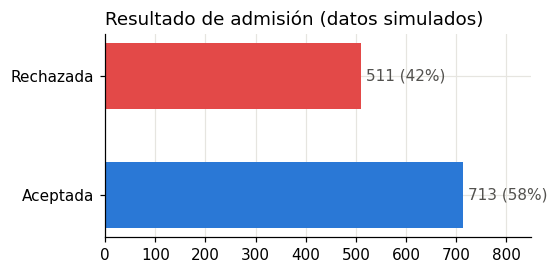

In [4]:
counts = df["resultado_admision"].value_counts()
print(counts, "\n", (counts / len(df) * 100).round(1))
fig, ax = plt.subplots(figsize=(5, 2.4))
ax.barh(counts.index, counts.values, color=[BLUE, RED], height=0.55)
for i, v in enumerate(counts.values):
    ax.text(v + 10, i, f"{v} ({v/len(df):.0%})", va="center", color=GREY)
ax.set_title("Resultado de admisión (datos simulados)", loc="left"); ax.set_xlim(0, 850)
plt.show()

Balance 58% / 42%: desbalance **leve**. Siguiendo el criterio de He y Garcia (2009), no amerita sobremuestreo (SMOTE) ni submuestreo; alcanza con un split estratificado. Nótese que esto difiere de la anticipación del Marco Teórico (donde se esperaba mayor proporción de rechazos, por Engstrom & Holland-Stergar, 2026): en la simulación construida a partir de los parámetros relevados en el estudio, la aceptación es mayoritaria.

## 3. Distribución de los predictores categóricos y tasa de admisión

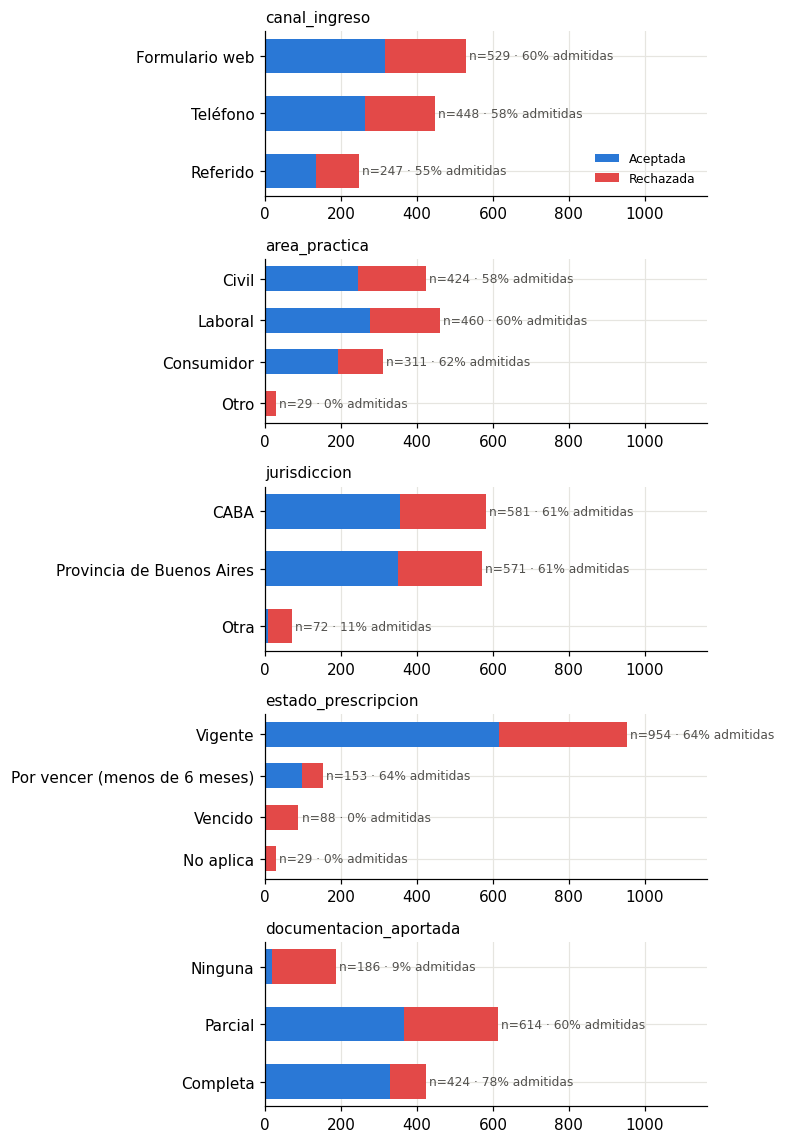

In [5]:
categorical = ["canal_ingreso", "area_practica", "jurisdiccion", "estado_prescripcion", "documentacion_aportada"]
fig, axes = plt.subplots(len(categorical), 1, figsize=(7, 2.1 * len(categorical)))
for ax, col in zip(axes, categorical):
    table = pd.crosstab(df[col], df["resultado_admision"]).reindex(DOMAINS[col]).fillna(0)
    rate = table["Aceptada"] / table.sum(axis=1)
    ax.barh(table.index, table["Aceptada"], color=BLUE, height=0.6, label="Aceptada")
    ax.barh(table.index, table["Rechazada"], left=table["Aceptada"], color=RED, height=0.6, label="Rechazada")
    for i, (n, t) in enumerate(zip(table.sum(axis=1), rate)):
        ax.text(n + 8, i, f"n={int(n)} · {t:.0%} admitidas", va="center", fontsize=8, color=GREY)
    ax.set_title(col, loc="left", fontsize=10); ax.invert_yaxis(); ax.set_xlim(0, df.shape[0] * 0.95)
axes[0].legend(loc="lower right", frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

In [6]:
for col in categorical:
    print(pd.crosstab(df[col], df["resultado_admision"], normalize="index").mul(100).round(1), "\n")

resultado_admision  Aceptada  Rechazada
canal_ingreso                          
Formulario web          59.7       40.3
Referido                54.7       45.3
Teléfono                58.5       41.5 

resultado_admision  Aceptada  Rechazada
area_practica                          
Civil                   57.8       42.2
Consumidor              61.7       38.3
Laboral                 60.0       40.0
Otro                     0.0      100.0 

resultado_admision         Aceptada  Rechazada
jurisdiccion                                  
CABA                           61.3       38.7
Otra                           11.1       88.9
Provincia de Buenos Aires      61.1       38.9 

resultado_admision             Aceptada  Rechazada
estado_prescripcion                               
No aplica                           0.0      100.0
Por vencer (menos de 6 meses)      64.1       35.9
Vencido                             0.0      100.0
Vigente                            64.5       35.5 

resultado_a

**Lectura (coherente con la lógica de generación documentada en Recolección de Datos, Módulo 2):**

- **Reglas de exclusión:** toda consulta del área *Otro* y toda consulta con plazo *Vencido* (o *No aplica*, que coincide con *Otro*) es rechazada en el 100% de los casos.
- **Documentación aportada** es el factor dominante entre las consultas restantes: Completa ≈78% de admisión, Parcial ≈60%, Ninguna ≈9%.
- Canal y jurisdicción muestran diferencias menores (salvo jurisdicción *Otra*, asociada al motivo "Jurisdicción fuera de cobertura").

## 4. Tipo de reclamo (25 categorías)

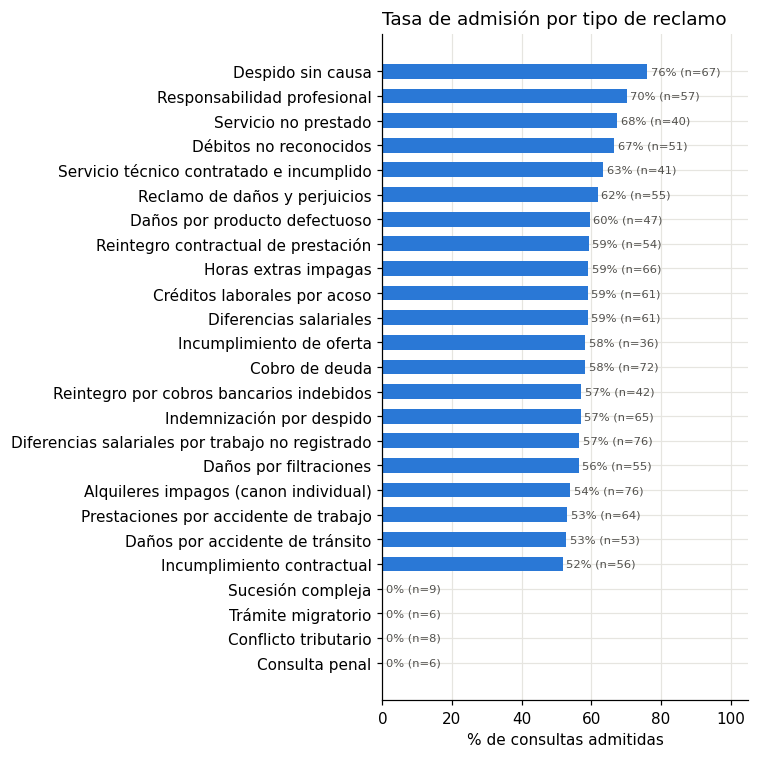

In [7]:
rate_by_type = (df.groupby("tipo_reclamo")["resultado_admision"]
             .agg(n="size", tasa_admision=lambda s: (s == "Aceptada").mean())
             .sort_values("tasa_admision"))
fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(rate_by_type.index, rate_by_type["tasa_admision"] * 100, color=BLUE, height=0.6)
for i, (n, t) in enumerate(zip(rate_by_type["n"], rate_by_type["tasa_admision"])):
    ax.text(t * 100 + 1, i, f"{t:.0%} (n={n})", va="center", fontsize=7.5, color=GREY)
ax.set_xlim(0, 105); ax.set_xlabel("% de consultas admitidas")
ax.set_title("Tasa de admisión por tipo de reclamo", loc="left"); plt.tight_layout(); plt.show()

Los tipos ajenos a las áreas del estudio (sucesión compleja, conflicto tributario, trámite migratorio, consulta penal) concentran los rechazos por *Fuera del área de práctica*; entre los restantes hay variación secundaria, tal como se especificó en la simulación.

## 5. Monto estimado: distribución, atípicos y relación con el target

count         1,086
mean     10,142,744
std       7,737,858
min         310,000
25%       3,292,500
50%       8,380,000
75%      16,027,500
max      32,550,000
Name: monto_estimado, dtype: object
Atípicos por IQR (>35,130,000): 0


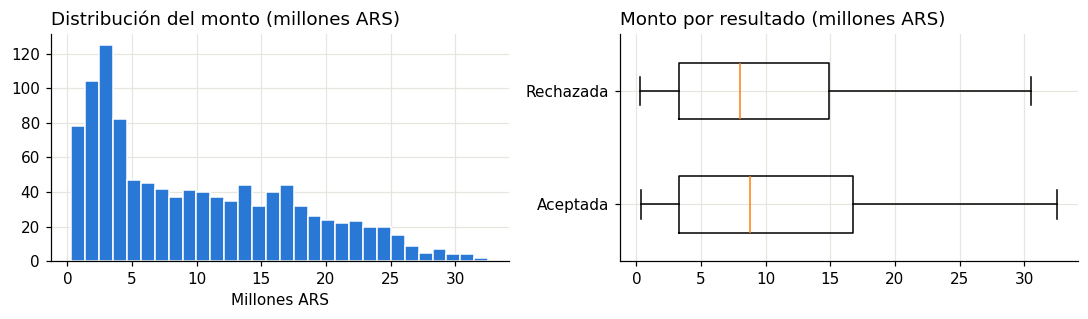

In [8]:
m = df["monto_estimado"]
print(m.describe().apply(lambda v: f"{v:,.0f}"))
q1, q3 = m.quantile([.25, .75]); iqr = q3 - q1
print(f"Atípicos por IQR (>{q3 + 1.5*iqr:,.0f}): {(m > q3 + 1.5*iqr).sum()}")
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(m.dropna() / 1e6, bins=30, color=BLUE, edgecolor="white")
axes[0].set_title("Distribución del monto (millones ARS)", loc="left"); axes[0].set_xlabel("Millones ARS")
groups = [df.loc[df.resultado_admision == r, "monto_estimado"].dropna() / 1e6 for r in ["Aceptada", "Rechazada"]]
axes[1].boxplot(groups, tick_labels=["Aceptada", "Rechazada"], vert=False, widths=0.5)
axes[1].set_title("Monto por resultado (millones ARS)", loc="left")
plt.tight_layout(); plt.show()

In [9]:
df.assign(monto_informado=df["monto_estimado"].notna()).pipe(
    lambda d: pd.crosstab(d["monto_informado"], d["resultado_admision"], normalize="index").mul(100).round(1))

resultado_admision,Aceptada,Rechazada
monto_informado,,
False,57.2,42.8
True,58.4,41.6


In [10]:
df.groupby("area_practica")["monto_estimado"].median().apply(lambda v: f"{v:,.0f}")

area_practica
Civil         10,510,000
Consumidor     2,190,000
Laboral       15,540,000
Otro           5,520,000
Name: monto_estimado, dtype: object

No hay atípicos extremos por el criterio IQR; la distribución es asimétrica a derecha, lo cual no afecta a un modelo basado en árboles (no requiere escalado ni transformación). El monto en sí muestra poca relación directa con el resultado, mientras que **su ausencia** sí se asocia a una menor tasa de admisión, lo que respalda la decisión de agregar la variable binaria `monto_informado` y dejar el `NaN` nativo para XGBoost en lugar de imputar.

## 6. Distribución temporal y coherencia con los parámetros relevados

Meses: 24 · consultas/mes: min 40, max 60, media 51.0


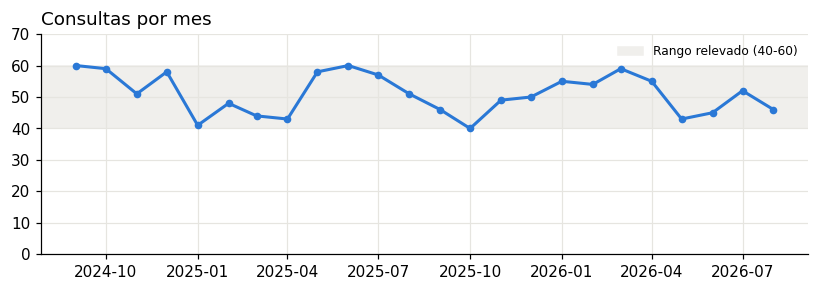

In [11]:
per_month = pd.Series(pd.to_datetime(df["fecha_consulta"])).dt.to_period("M").value_counts().sort_index()
print(f"Meses: {len(per_month)} · consultas/mes: min {per_month.min()}, max {per_month.max()}, media {per_month.mean():.1f}")
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.plot(per_month.index.to_timestamp(), per_month.values, color=BLUE, lw=2, marker="o", ms=4)
ax.axhspan(40, 60, color="#f0efec", zorder=0, label="Rango relevado (40-60)")
ax.set_title("Consultas por mes", loc="left"); ax.legend(frameon=False, fontsize=8); ax.set_ylim(0, 70)
plt.show()

El volumen mensual simulado se mantiene dentro del rango de 40 a 60 consultas relevado en el Módulo 2.

## 7. Columnas excluidas del modelo

In [12]:
pd.crosstab(df["resultado_final_caso"], df["resultado_admision"])

resultado_admision,Aceptada,Rechazada
resultado_final_caso,,
Acuerdo,202,0
En trámite,370,0
Ganado,104,0
No aplica,0,511
Perdido,37,0


`resultado_final_caso` solo toma valores distintos de *No aplica* en las consultas aceptadas: incluirla como predictor equivaldría a revelarle al modelo la respuesta (**fuga de información**). Se excluye junto con `socio_evaluador` (metadato del proceso), `motivo_rechazo` (posterior a la decisión) y las columnas de soporte del cálculo de prescripción.

## Conclusiones del EDA
1. Dataset sin problemas de calidad estructural: 1224 filas, dominios cerrados que coinciden con los del formulario de intake, único faltante relevante en `monto_estimado`.
2. Desbalance leve (58/42): split estratificado, sin remuestreo.
3. Las relaciones observadas reproducen la lógica de generación documentada (exclusiones automáticas + documentación como factor principal). El modelo aprenderá **esos supuestos**, no evidencia del proceso real: es la limitación central del enfoque de prueba de concepto (Riesgo R1/R2).